# Figure 3

Redraws every data panel of Figure 3 from the source data workbook `Figure_3.xlsx`.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib import font_manager

SOURCE = Path("..") / "Source data"                     # relative to this notebook's folder
BOOK = SOURCE / "Figure_3.xlsx"

FONT = "Calibri" if any(f.name == "Calibri" for f in font_manager.fontManager.ttflist) else "Carlito"
BASE, LETTER = 7.5, 10.5                                        # all text 7.5 pt; panel letters 10.5 pt bold
MM = 1 / 25.4
WIDTH = 180 * MM                                                # width of the published figure (in)
INK, INK3, GRIDC, NAVY = "#0b0b0b", "#76756f", "#eeeeec", "#22314a"
COL = {"local": "#2f6db5", "inbound": "#1a9e6f", "outbound": "#e86a33"}
TEAL, CORAL, GREY, LAND, EDGE = "#1795a3", "#d9644f", "#c7c6c1", "#f4f3f0", "#ffffff"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": [FONT], "mathtext.fontset": "custom",
    "mathtext.rm": FONT, "mathtext.it": f"{FONT}:italic", "mathtext.bf": f"{FONT}:bold",
    "mathtext.cal": FONT, "mathtext.sf": FONT, "mathtext.tt": FONT,
    "font.size": BASE, "axes.labelsize": BASE, "xtick.labelsize": BASE, "ytick.labelsize": BASE,
    "legend.fontsize": BASE, "axes.titlesize": BASE, "legend.title_fontsize": BASE, "legend.labelcolor": INK,
    "text.color": INK, "axes.edgecolor": INK3, "axes.linewidth": 0.5, "xtick.color": INK3, "ytick.color": INK3,
    "xtick.labelcolor": INK, "ytick.labelcolor": INK, "axes.labelcolor": INK,
    "xtick.major.width": 0.5, "ytick.major.width": 0.5, "xtick.major.size": 2, "ytick.major.size": 2,
    "xtick.major.pad": 1.5, "ytick.major.pad": 1.5, "axes.labelpad": 2,
    "legend.frameon": False, "axes.unicode_minus": True,
    "figure.dpi": 300, "figure.facecolor": "white", "figure.edgecolor": "white", "savefig.facecolor": "white"})
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}


def panel_figure(x0, y0, w, h):
    """One panel as a standalone figure; positions are inches from the lower-left corner of the published figure."""
    fig = plt.figure(figsize=(w, h))

    def ax_in(x, y, ww, hh, **kw):
        return fig.add_axes([(x - x0) / w, (y - y0) / h, ww / w, hh / h], **kw)

    def letter(x, y, s):
        fig.text((x - x0) / w, (y - y0) / h, s, fontsize=LETTER, fontweight="bold", color=INK, va="top", ha="left")

    def T(x, y, s, **kw):
        kw.setdefault("fontsize", BASE)
        kw.setdefault("color", INK)
        return fig.text((x - x0) / w, (y - y0) / h, s, **kw)

    return fig, ax_in, letter, T


def overlay(ax_in, x0, y0, w, h):
    """Transparent axes covering the panel, with data coordinates in inches of the published figure."""
    ov = ax_in(x0, y0, w, h)
    ov.set_xlim(x0, x0 + w)
    ov.set_ylim(y0, y0 + h)
    ov.axis("off")
    ov.patch.set_alpha(0)
    return ov


def clean(ax, grid="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    if grid:
        ax.grid(axis=grid, color=GRIDC, lw=0.5)
        ax.set_axisbelow(True)


def nfmt(v, nd=1):
    return f"{v:.{nd}f}".replace("-", "\u2212")


def mfmt(v, nd=1):
    return f"{v:+.{nd}f}".replace("-", "\u2212")


def pfmt(p):
    return r"$P$ < 0.001" if p < 0.001 else rf"$P$ = {p:.3f}" if p < 0.01 else rf"$P$ = {p:.2f}"

from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

OCHRE = "#c98f1f"
C_CMAP = LinearSegmentedColormap.from_list("C", ["#f6ebe7", "#eba793", CORAL, "#8e3a2b"])
A_RAMP = LinearSegmentedColormap.from_list("A", ["#f6d5cc", CORAL])   # panel a bars: quintile 1 (light) to 5
PROD = {"ERA5": NAVY, "CPC": OCHRE, "CHIRPS": INK3}
RECORD = {"ERA5": "Reanalysis\n(ERA5-Land)", "CPC": "Rain gauges\n(CPC)", "CHIRPS": "Satellite–gauge\n(CHIRPS)"}
INB_LIGHT = "#bfe3d4"
LW_CI = 1.0
SLOT = 0.22                                                     # row pitch of panel d
CY = 0.36                                                       # bottom of the row-2 axes
Y2 = CY + 7 * SLOT + 0.40                                       # top of row 2
B1 = Y2 + 0.56                                                  # bottom of the panel a axes
T1 = B1 + 1.40                                                  # top of the panel a axes
H = T1 + 0.20                                                   # height of the published figure (in)

**Panel a**: partner demand hit by the same rainfall system by quintile of ex-ante S.

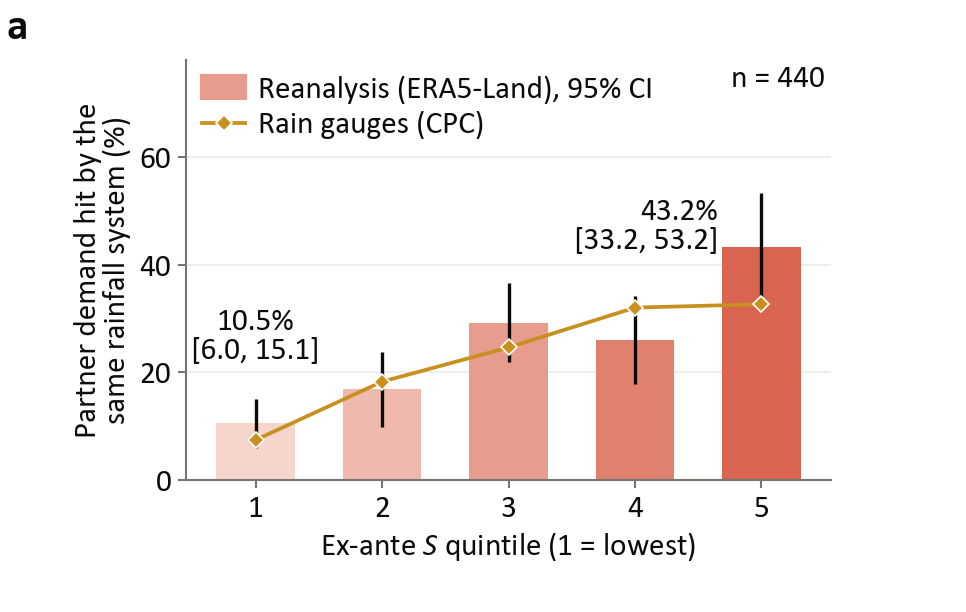

In [2]:
qa = pd.read_excel(BOOK, sheet_name="Fig3a").set_index("S_quintile")

X0, Y0, PW, PH = 0.0, 2.42, 3.22, H - 2.42
fig, ax_in, letter, T = panel_figure(X0, Y0, PW, PH)
letter(0.02, H - 0.03, "a")
AW_A = 2.15
axa = ax_in(0.62, B1, AW_A, T1 - B1)
clean(axa)
x = qa.index.to_numpy()
m, lo, hi = qa.partner_demand_hit_pct.to_numpy(), qa.ci_low_pct.to_numpy(), qa.ci_high_pct.to_numpy()
ramp = [A_RAMP(t) for t in np.linspace(0, 1, len(x))]
axa.bar(x, m, width=0.62, color=ramp, edgecolor="none", zorder=1)
axa.vlines(x, lo, hi, color=INK, lw=0.8, zorder=3)
axa.plot(x, qa.cpc_partner_demand_hit_pct, color=OCHRE, lw=0.9, marker="D", ms=2.8, mfc=OCHRE, mec="white", mew=0.4,
         zorder=4)
axa.text(1.0, hi[0] + 6.3, f"{m[0]:.1f}%\n[{lo[0]:.1f}, {hi[0]:.1f}]", fontsize=BASE, color=INK, ha="center",
         va="bottom", linespacing=1.05)
axa.text(4.66, 47.0, f"{m[4]:.1f}%\n[{lo[4]:.1f}, {hi[4]:.1f}]", fontsize=BASE, color=INK, ha="right", va="center",
         linespacing=1.05)
axa.text(5.50, 77.0, f"n = {int(qa.n_events.sum())}", fontsize=BASE, color=INK, ha="right", va="top")
axa.set_xlim(0.45, 5.55)
axa.set_ylim(0, 78)
axa.set_yticks([0, 20, 40, 60])
axa.set_xticks(x)
axa.set_xlabel(r"Ex-ante $S$ quintile (1 = lowest)")
axa.set_ylabel("Partner demand hit by the\nsame rainfall system (%)", linespacing=1.05)
axa.legend(handles=[Rectangle((0, 0), 1, 1, color=A_RAMP(0.5), label="Reanalysis (ERA5-Land), 95% CI"),
                    Line2D([], [], color=OCHRE, lw=0.9, marker="D", ms=2.8, mfc=OCHRE, mec="white", mew=0.4,
                           label="Rain gauges (CPC)")],
           loc="upper left", handlelength=1.4, labelspacing=0.25, borderaxespad=0.1, handletextpad=0.4)
plt.show()

**Panel b**: partner demand hit per +0.10 S, with S and the outcome from three rainfall products.

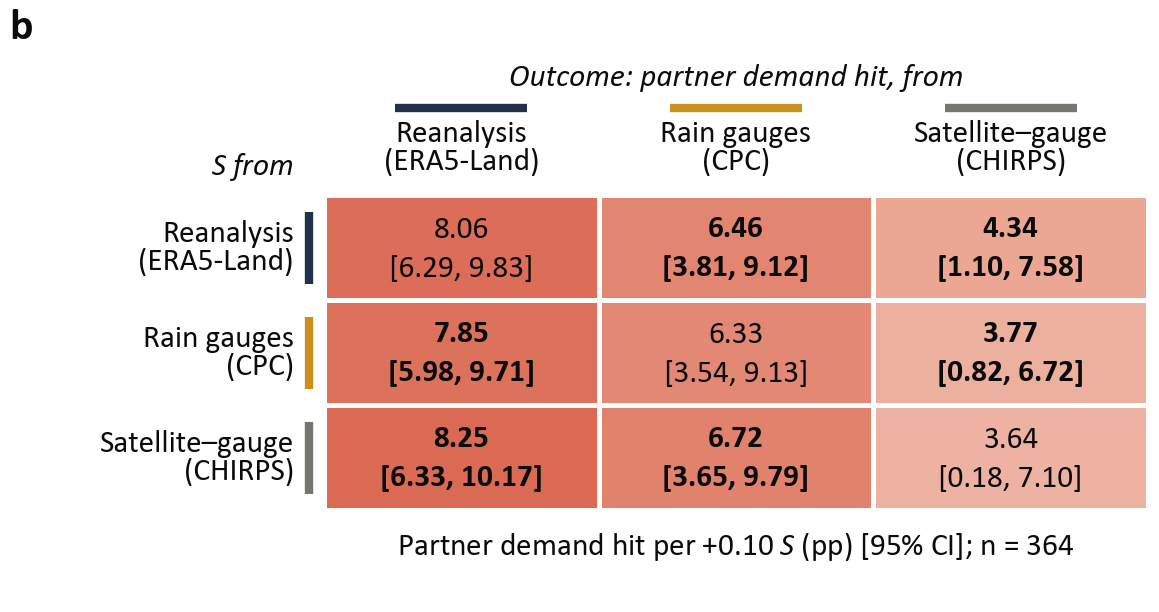

In [3]:
grid = pd.read_excel(BOOK, sheet_name="Fig3b")

X0, Y0, PW, PH = 3.22, 2.42, WIDTH - 3.22, H - 2.42
fig, ax_in, letter, T = panel_figure(X0, Y0, PW, PH)
BX = 3.25
letter(BX, H - 0.03, "b")
GX, GR = 4.30, WIDTH - 0.04
CW = (GR - GX) / 3
GB = B1 - 0.10
GTOP = T1 - 0.45
CH = (GTOP - GB) / 3
axb = ax_in(BX, GB - 0.30, WIDTH - BX, GTOP + 0.50 - (GB - 0.30))
axb.set_xlim(BX, WIDTH)
axb.set_ylim(GB - 0.30, GTOP + 0.50)
axb.set_axis_off()
NORM = Normalize(0, 13)
order = ["ERA5", "CPC", "CHIRPS"]
for j, c in enumerate(order):
    cx = GX + j * CW + CW / 2
    axb.plot([cx - 0.22, cx + 0.22], [GTOP + 0.29, GTOP + 0.29], color=PROD[c], lw=2.0, solid_capstyle="butt")
    axb.text(cx, GTOP + 0.25, RECORD[c], fontsize=BASE, color=INK, ha="center", va="top", linespacing=1.0)
axb.text(GX + 1.5 * CW, GTOP + 0.345, "Outcome: partner demand hit, from", fontsize=BASE, color=INK,
         ha="center", va="bottom", fontstyle="italic")
axb.text(GX - 0.10, GTOP + 0.04, r"$S$ from", fontsize=BASE, color=INK, ha="right", va="bottom", fontstyle="italic")
for i, rp in enumerate(order):
    cy = GTOP - i * CH - CH / 2
    axb.plot([GX - 0.05, GX - 0.05], [cy - 0.12, cy + 0.12], color=PROD[rp], lw=2.0, solid_capstyle="butt")
    axb.text(GX - 0.10, cy, RECORD[rp], fontsize=BASE, color=INK, ha="right", va="center", linespacing=1.0)
    for j, c in enumerate(order):
        r = grid.loc[(grid.S_product == rp) & (grid.outcome_product == c)].iloc[0]
        x0, y0 = GX + j * CW, GTOP - (i + 1) * CH
        weight = "bold" if r.cross_product_bold == 1 else "normal"
        axb.add_patch(Rectangle((x0, y0), CW, CH, facecolor=C_CMAP(NORM(r.pp_per_0p1_S)), edgecolor="white", lw=1.2,
                                zorder=1))
        axb.text(x0 + CW / 2, y0 + CH * 0.67, f"{r.pp_per_0p1_S:.2f}", fontsize=BASE, color=INK, ha="center",
                 va="center", fontweight=weight, zorder=3)
        axb.text(x0 + CW / 2, y0 + CH * 0.30, f"[{r.ci_low:.2f}, {r.ci_high:.2f}]", fontsize=BASE, color=INK,
                 ha="center", va="center", fontweight=weight, zorder=3)
axb.text(GX + 1.5 * CW, GB - 0.07, r"Partner demand hit per +0.10 $S$ (pp) [95% CI]; "
         + f"n = {int(grid.n_events.iloc[0])}", fontsize=BASE, color=INK, ha="center", va="top")
plt.show()

**Panel c**: calibration of ex-ante S against the share later hit (decile means and pooled fits).

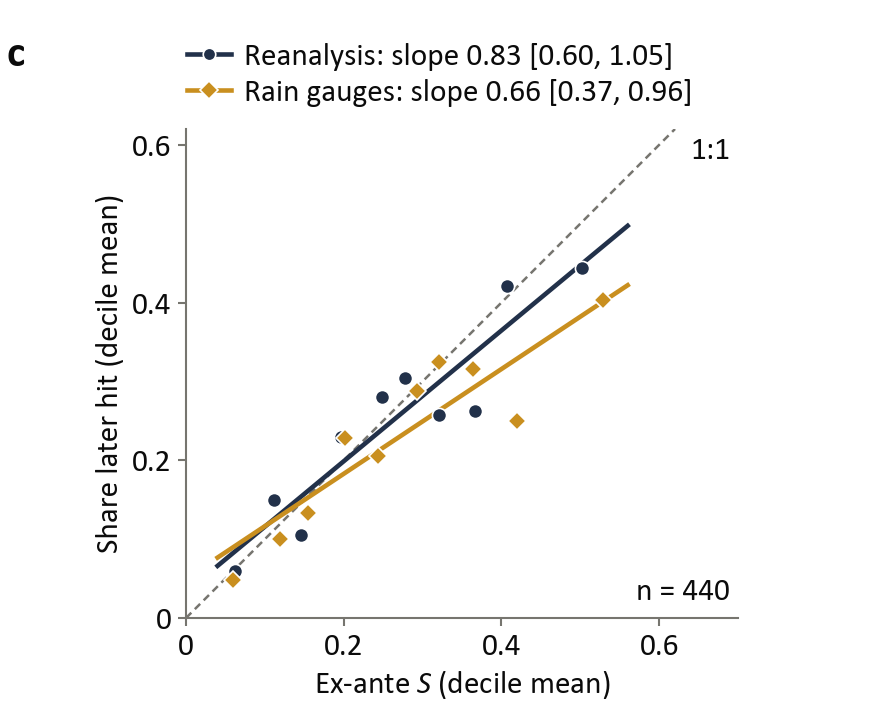

In [4]:
pts = pd.read_excel(BOOK, sheet_name="Fig3c_points")
fits = pd.read_excel(BOOK, sheet_name="Fig3c_fits").set_index("product")

X0, Y0, PW, PH = 0.0, 0.0, 2.95, 2.42
fig, ax_in, letter, T = panel_figure(X0, Y0, PW, PH)
letter(0.02, Y2, "c")
LIM, LIMX = (0, 0.62), (0, 0.70)
CH_C = Y2 - 0.31 - CY
CW_C = CH_C * (LIMX[1] - LIMX[0]) / (LIM[1] - LIM[0])
axc = ax_in(0.62, CY, CW_C, CH_C)
clean(axc, grid=None)
axc.plot(LIM, LIM, color=INK3, lw=0.6, ls=(0, (3, 2)), zorder=1)
axc.text(0.69, 0.61, "1:1", fontsize=BASE, color=INK, ha="right", va="top")
xs = np.linspace(0.04, 0.56, 50)
hd = []
for prod, mk in (("ERA5", "o"), ("CPC", "D")):
    f, p = fits.loc[prod], pts.loc[pts["product"] == prod]
    axc.plot(xs, f.intercept + f.slope * xs, color=PROD[prod], lw=1.1, zorder=2)
    axc.plot(p.mean_S, p.mean_share_later_hit, ls="", marker=mk, ms=3.4 if mk == "o" else 3.0, mfc=PROD[prod],
             mec="white", mew=0.4, zorder=3)
    lab = f"{f.label}: slope {f.slope:.2f} [{f.slope_ci_low:.2f}, {f.slope_ci_high:.2f}]"
    hd.append(Line2D([], [], color=PROD[prod], lw=1.1, marker=mk, ms=3.0, mfc=PROD[prod], mec="white", mew=0.4,
                     label=lab))
axc.legend(handles=hd, loc="lower left", bbox_to_anchor=(-0.02, 1.02), handlelength=1.4, labelspacing=0.25,
           borderaxespad=0.0, handletextpad=0.4)
n_c = int(pts.loc[pts["product"] == "ERA5", "n_events"].sum())
axc.text(0.69, 0.015, f"n = {n_c}", fontsize=BASE, color=INK, ha="right", va="bottom")
axc.set_xlim(*LIMX)
axc.set_ylim(*LIM)
axc.set_aspect("equal")
for setter in (axc.set_xticks, axc.set_yticks):
    setter([0, 0.2, 0.4, 0.6])
axc.set_xticklabels(["0", "0.2", "0.4", "0.6"])
axc.set_yticklabels(["0", "0.2", "0.4", "0.6"])
axc.set_xlabel(r"Ex-ante $S$ (decile mean)")
axc.set_ylabel("Share later hit (decile mean)")
plt.show()

**Panel d**: spending change per +10 pp of partner demand hit in a city without extreme rain (upper) and the day-0 inbound change when the city is hit (lower).

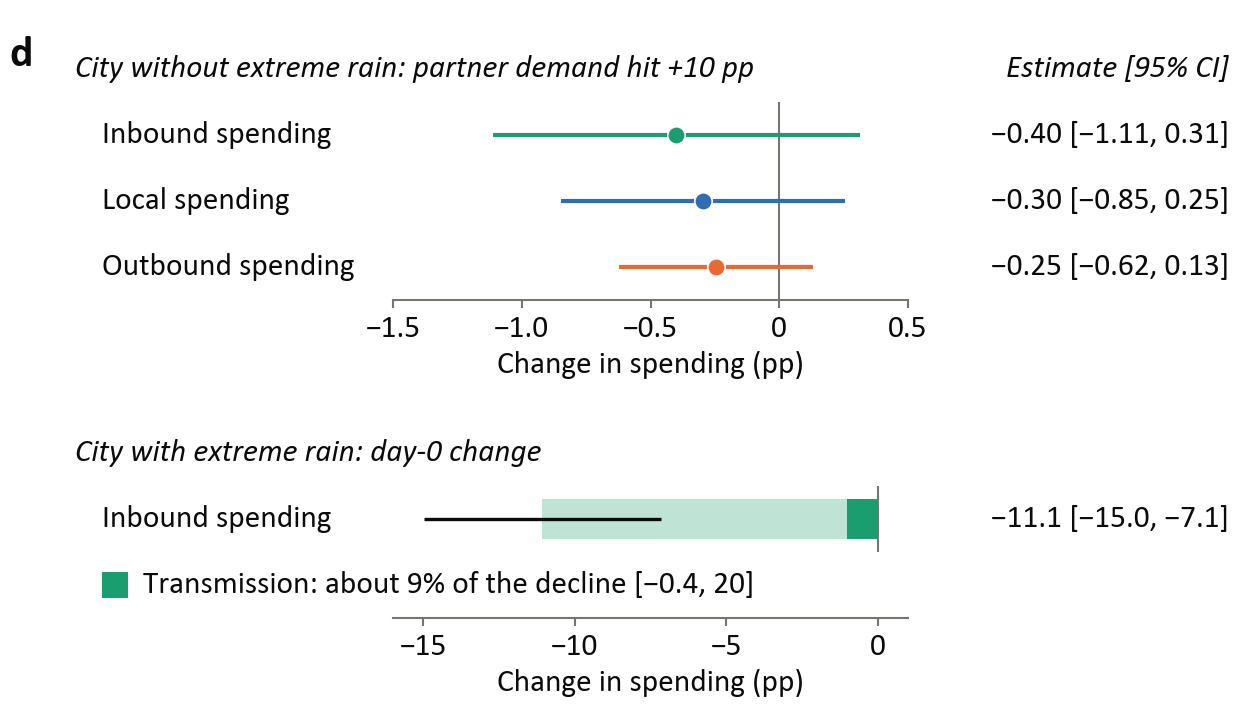

In [5]:
up = pd.read_excel(BOOK, sheet_name="Fig3d_upper").set_index("margin")
low = pd.read_excel(BOOK, sheet_name="Fig3d_lower")

X0, Y0, PW, PH = 2.95, 0.0, WIDTH - 2.95, 2.42
fig, ax_in, letter, T = panel_figure(X0, Y0, PW, PH)
CH_C = Y2 - 0.31 - CY
CW_C = CH_C * 0.70 / 0.62
DLX = 0.62 + CW_C + 0.52
letter(DLX, Y2, "d")
LX, VX = DLX + 0.22, WIDTH - 0.04
AX = LX + 1.06
AW = VX - 1.07 - AX
yL0, yL1 = CY, CY + 2 * SLOT
yU0 = yL1 + SLOT + 0.40
yU1 = yU0 + 3 * SLOT


def style(ax):
    clean(ax, grid=None)
    ax.spines["left"].set_visible(False)
    ax.set_yticks([])
    ax.set_xlabel("Change in spending (pp)")


T(LX, yU1 + SLOT / 2, "City without extreme rain: partner demand hit +10 pp", ha="left", va="center", fontstyle="italic")
T(VX, yU1 + SLOT / 2, "Estimate [95% CI]", ha="right", va="center", fontstyle="italic")
axu = ax_in(AX, yU0, AW, yU1 - yU0)
style(axu)
axu.set_xlim(-1.5, 0.5)
axu.set_ylim(3.5, 0.5)
axu.set_xticks([-1.5, -1.0, -0.5, 0, 0.5])
axu.set_xticklabels(["\u22121.5", "\u22121.0", "\u22120.5", "0", "0.5"])
axu.axvline(0, color=INK3, lw=0.5, zorder=1)
for k, (key, lab) in enumerate((("inbound", "Inbound spending"), ("local", "Local spending"),
                                ("outbound", "Outbound spending")), start=1):
    r, yk = up.loc[lab], yU1 - (k - 0.5) * SLOT
    axu.plot([r.ci_low, r.ci_high], [k, k], color=COL[key], lw=LW_CI, solid_capstyle="butt", zorder=2)
    axu.plot([r.change_pp_per_10pp], [k], ls="", marker="o", ms=4.2, mfc=COL[key], mec="white", mew=0.4, zorder=3)
    T(LX + 0.09, yk, lab, ha="left", va="center")
    T(VX, yk, f"{nfmt(r.change_pp_per_10pp, 2)} [{nfmt(r.ci_low, 2)}, {nfmt(r.ci_high, 2)}]", ha="right", va="center")
T(LX, yL1 + SLOT / 2, "City with extreme rain: day-0 change", ha="left", va="center", fontstyle="italic")
axl = ax_in(AX, yL0, AW, yL1 - yL0)
style(axl)
axl.set_xlim(-16, 1)
axl.set_ylim(2.5, 0.5)
axl.set_xticks([-15, -10, -5, 0])
axl.set_xticklabels(["\u221215", "\u221210", "\u22125", "0"])
day0 = low.loc[low.item.str.startswith("day-0")].iloc[0]
implied = low.loc[low.item.str.startswith("part implied")].iloc[0]
D = low.loc[low.item.str.startswith("transmission")].iloc[0]
axl.plot([0, 0], [0.5, 1.5], color=INK3, lw=0.5, zorder=1, solid_capstyle="butt")
axl.barh(1, day0.estimate, height=0.62, color=INB_LIGHT, edgecolor="none", zorder=1.5)
axl.barh(1, implied.estimate, height=0.62, color=COL["inbound"], edgecolor="none", zorder=1.6)
axl.plot([day0.ci_low, day0.ci_high], [1, 1], color=INK, lw=0.8, solid_capstyle="butt", zorder=3)
T(LX + 0.09, yL1 - 0.5 * SLOT, "Inbound spending", ha="left", va="center")
T(VX, yL1 - 0.5 * SLOT, f"{nfmt(day0.estimate, 1)} [{nfmt(day0.ci_low, 1)}, {nfmt(day0.ci_high, 1)}]", ha="right",
  va="center")
sw, yk = 0.085, yL1 - 1.5 * SLOT
fig.patches.append(Rectangle(((LX + 0.09 - X0) / PW, (yk - sw / 2 - Y0) / PH), sw / PW, sw / PH,
                             transform=fig.transFigure, facecolor=COL["inbound"], edgecolor="none"))
T(LX + 0.09 + sw + 0.05, yk, f"Transmission: about {100 * D.estimate:.0f}% of the decline "
  f"[{nfmt(100 * D.ci_low, 1)}, {100 * D.ci_high:.0f}]", ha="left", va="center")
plt.show()